Resources for analysis

* https://bioinformaticsworkbook.org/tutorials/wgcna.html#gsc.tab=0

## Set Library Path

In [1]:
.libPaths("/home/vhaghani/anaconda3/envs/jupyter_nb_R4.4.2/lib/R/library")

## Load Libraries

In [3]:
library(tidyverse)
library(WGCNA)
library(magrittr)
library(biomaRt)

## Load Data

In [4]:
# Read in normalized gene counts from DEG analysis
counts <- read.delim("05_gene_counts/MECP2_normalized_counts.txt", row.names = 1)

# Fix column naming
colnames(counts) <- gsub("^X", "", colnames(counts))

# View data
head(counts)

,2043_D_MECP2_WT_CtO_D46_1,2043_D_MECP2_WT_CtO_D46_2,2043_D_MECP2_WT_CtO_D46_3,2043_A_MECP2_R270X_CtO_D46_1,2043_A_MECP2_R270X_CtO_D46_2,2043_A_MECP2_R270X_CtO_D46_3,2043_A_MECP2_R270X_CtO_D18_1,2043_A_MECP2_R270X_CtO_D18_2,2043_D_MECP2_WT_CtO_D18_1,GM27437_MECP2_1155del32_CtOD111_1,⋯,GM27437_MECP2_1155del32_CtOD111_3,80230F_CtOD111_1,80230F_CtOD111_2,80230F_CtOD111_3,R270X_pA_ORG_d90_N1,R270X_pA_ORG_d90_N2,R270X_pA_ORG_d90_N3,R270X_pD_ORG_d90_N1,R270X_pD_ORG_d90_N2,R270X_pD_ORG_d90_N3
,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,⋯,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
A1BG,2.655037,4.469192,1.924255,1.924255,1.924255,1.924255,1.924255,3.019783,1.924255,1.924255,⋯,1.924255,1.924255,3.380704,3.213690,NA,NA,NA,NA,NA,0
A1BG-AS1,2.655037,1.924255,4.053531,1.924255,1.924255,4.858545,3.465801,1.924255,2.509062,3.898888,⋯,1.924255,3.729057,4.151520,5.232654,NA,NA,NA,NA,NA,0
A1CF,1.924255,1.924255,1.924255,1.924255,1.924255,3.336196,1.924255,1.924255,1.924255,1.924255,⋯,1.924255,1.924255,1.924255,4.684964,NA,NA,NA,NA,NA,0
A2M,3.787462,1.924255,1.924255,2.856358,1.924255,2.796473,8.498343,7.690715,5.923817,5.958469,⋯,4.786391,4.347610,4.372550,6.456964,NA,NA,NA,NA,NA,0
A2M-AS1,1.924255,1.924255,1.924255,1.924255,1.924255,1.924255,3.109514,4.782837,1.924255,1.924255,⋯,1.924255,1.924255,2.179833,3.349201,NA,NA,NA,NA,NA,0
A2ML1,1.924255,1.924255,4.878443,6.696858,3.789491,4.505088,1.924255,3.360081,3.245903,1.924255,⋯,3.913551,3.729057,3.037209,4.402888,NA,NA,NA,NA,NA,0


In [5]:
# Transpose for WGCNA
counts <- t(counts)

# Sort counts by row names
counts <- counts[order(rownames(counts)), ]

# View
head(counts)

,A1BG,A1BG-AS1,A1CF,A2M,A2M-AS1,A2ML1,A2ML1-AS1,A4GALT,AAAS,AACS,⋯,ZWILCH,ZWINT,ZXDA,ZXDB,ZXDC,ZYG11A,ZYG11B,ZYX,ZZEF1,ZZZ3
2043_A_MECP2_R270X_CtO_D18_1,1.924255,3.465801,1.924255,8.498343,3.109514,1.924255,2.635328,3.109514,5.408694,5.234347,⋯,4.925558,4.372930,4.193924,4.532157,4.372930,1.924255,5.138577,6.110087,5.408694,6.058685
2043_A_MECP2_R270X_CtO_D18_2,3.019783,1.924255,1.924255,7.690715,4.782837,3.360081,3.019783,1.924255,4.992915,4.992915,⋯,3.635233,3.019783,3.635233,2.573601,4.665089,1.924255,5.552927,5.552927,5.796390,6.143203
2043_A_MECP2_R270X_CtO_D46_1,1.924255,1.924255,1.924255,2.856358,1.924255,6.696858,1.924255,1.924255,1.924255,1.924255,⋯,1.924255,1.924255,1.924255,1.924255,1.924255,1.924255,1.924255,4.971172,1.924255,1.924255
2043_A_MECP2_R270X_CtO_D46_2,1.924255,1.924255,1.924255,1.924255,1.924255,3.789491,1.924255,1.924255,1.924255,1.924255,⋯,1.924255,7.269407,1.924255,1.924255,1.924255,4.576523,1.924255,5.082887,1.924255,1.924255
2043_A_MECP2_R270X_CtO_D46_3,1.924255,4.858545,3.336196,2.796473,1.924255,4.505088,1.924255,1.924255,3.728071,4.692614,⋯,3.336196,1.924255,4.035921,4.289492,5.379181,2.796473,5.842457,5.582655,6.192573,6.311852
2043_D_MECP2_WT_CtO_D18_1,1.924255,2.509062,1.924255,5.923817,1.924255,3.245903,2.924022,1.924255,4.923847,4.245810,⋯,4.624300,5.245763,2.924022,3.508906,5.383262,1.924255,5.567682,5.383262,5.678710,6.596232


### Set Up Metadata

In [6]:
# Load WGCNA metadata
metadata <- read.csv("wgcna_metadata.csv")

# Set row names
rownames(metadata) <- metadata$Sample
metadata$Sample <- NULL

# Sort metadata by row names
metadata <- metadata[order(rownames(metadata)), ]

# View
head(metadata)

,WT_D18_vs_R270X_D18,WT_D18_vs_WT_D46,WT_D18_vs_R270X_D46,WT_D18_vs_X80230F_WT_D111,WT_D18_vs_1155del32_D111,WT_D18_vs_R270X_pA_D90,WT_D18_vs_R270X_pD_D90,R270X_D18_vs_WT_D46,R270X_D18_vs_R270X_D46,R270X_D18_vs_X80230F_WT_D111,⋯,R270X_pA_D90_vs_R270X_pD_D90,All_WT_vs_All_MUT,All_D18,All_D46,All_D90,All_D111,Decreased_GAD1_Expression,Decreased_FOXG1_Expression,Decreased_Organoid_Area,Impaired_Neurite_Outgrowth
,<int>,<int>,<int>,<int>,<int>,<int>,<int>,<int>,<int>,<int>,⋯,<int>,<int>,<int>,<int>,<int>,<int>,<int>,<int>,<int>,<int>
2043_A_MECP2_R270X_CtO_D18_1,1,NA,NA,NA,NA,NA,NA,0,0,0,⋯,NA,1,1,0,0,0,1,1,NA,NA
2043_A_MECP2_R270X_CtO_D18_2,1,NA,NA,NA,NA,NA,NA,0,0,0,⋯,NA,1,1,0,0,0,1,1,NA,NA
2043_A_MECP2_R270X_CtO_D46_1,NA,NA,1,NA,NA,NA,NA,NA,1,NA,⋯,NA,1,0,1,0,0,1,1,NA,NA
2043_A_MECP2_R270X_CtO_D46_2,NA,NA,1,NA,NA,NA,NA,NA,1,NA,⋯,NA,1,0,1,0,0,1,1,NA,NA
2043_A_MECP2_R270X_CtO_D46_3,NA,NA,1,NA,NA,NA,NA,NA,1,NA,⋯,NA,1,0,1,0,0,0,0,NA,NA
2043_D_MECP2_WT_CtO_D18_1,0,0,0,0,0,0,0,NA,NA,NA,⋯,NA,0,1,0,0,0,1,1,NA,NA


In [7]:
rownames(metadata)
rownames(counts)

[1] "2043_A_MECP2_R270X_CtO_D18_1"      "2043_A_MECP2_R270X_CtO_D18_2"     
 [3] "2043_A_MECP2_R270X_CtO_D46_1"      "2043_A_MECP2_R270X_CtO_D46_2"     
 [5] "2043_A_MECP2_R270X_CtO_D46_3"      "2043_D_MECP2_WT_CtO_D18_1"        
 [7] "2043_D_MECP2_WT_CtO_D46_1"         "2043_D_MECP2_WT_CtO_D46_2"        
 [9] "2043_D_MECP2_WT_CtO_D46_3"         "80230F_CtOD111_1"                 
[11] "80230F_CtOD111_2"                  "80230F_CtOD111_3"                 
[13] "GM27437_MECP2_1155del32_CtOD111_1" "GM27437_MECP2_1155del32_CtOD111_2"
[15] "GM27437_MECP2_1155del32_CtOD111_3" "R270X_pA_ORG_d90_N1"              
[17] "R270X_pA_ORG_d90_N2"               "R270X_pA_ORG_d90_N3"              
[19] "R270X_pD_ORG_d90_N1"               "R270X_pD_ORG_d90_N2"              
[21] "R270X_pD_ORG_d90_N3"

[1] "2043_A_MECP2_R270X_CtO_D18_1"      "2043_A_MECP2_R270X_CtO_D18_2"     
 [3] "2043_A_MECP2_R270X_CtO_D46_1"      "2043_A_MECP2_R270X_CtO_D46_2"     
 [5] "2043_A_MECP2_R270X_CtO_D46_3"      "2043_D_MECP2_WT_CtO_D18_1"        
 [7] "2043_D_MECP2_WT_CtO_D46_1"         "2043_D_MECP2_WT_CtO_D46_2"        
 [9] "2043_D_MECP2_WT_CtO_D46_3"         "80230F_CtOD111_1"                 
[11] "80230F_CtOD111_2"                  "80230F_CtOD111_3"                 
[13] "GM27437_MECP2_1155del32_CtOD111_1" "GM27437_MECP2_1155del32_CtOD111_2"
[15] "GM27437_MECP2_1155del32_CtOD111_3" "R270X_pA_ORG_d90_N1"              
[17] "R270X_pA_ORG_d90_N2"               "R270X_pA_ORG_d90_N3"              
[19] "R270X_pD_ORG_d90_N1"               "R270X_pD_ORG_d90_N2"              
[21] "R270X_pD_ORG_d90_N3"

In [8]:
# Create a list of all datasets to match metadata and counts
datasets <- list(
  MECP2 = list(metadata = metadata, counts = counts)
)

In [9]:
# Check dimensions for all
for (cell_line in names(datasets)) {
  cat(paste0(cell_line, " dimensions:\n"))
  cat("Metadata:", dim(datasets[[cell_line]]$metadata), "\n")
  cat("Counts:", dim(datasets[[cell_line]]$counts), "\n")
  cat("Row names match:", identical(rownames(datasets[[cell_line]]$metadata), 
                                   rownames(datasets[[cell_line]]$counts)), "\n\n")
}

MECP2 dimensions:
Metadata: 21 37 
Counts: 21 25210 
Row names match: TRUE 



## WGCNA

### Soft Power Threshold

In [10]:
# Allow multi-threading
allowWGCNAThreads() 

# Choose a set of soft-thresholding powers
powers = c(c(1:10), seq(from = 12, to = 25, by = 1))

# Create a list to store results
sft_results <- list()

# Iterate through all datasets
for (cell_line in names(datasets)) {
  cat(paste0("\nAnalyzing soft thresholds for: ", cell_line, "\n"))
  cat(paste0("Dataset dimensions: ", nrow(datasets[[cell_line]]$counts), 
             " samples x ", ncol(datasets[[cell_line]]$counts), " genes\n"))
  
  # Call the network topology analysis function for each cell line
  sft_results[[cell_line]] <- pickSoftThreshold(
    datasets[[cell_line]]$counts,             
    powerVector = powers,
    verbose = 5,
    networkType = "signed"
  )
  
  cat(paste0("Completed soft threshold analysis for: ", cell_line, "\n"))
}

Allowing multi-threading with up to 20 threads.

Analyzing soft thresholds for: MECP2
Dataset dimensions: 21 samples x 25210 genes
pickSoftThreshold: will use block size 1774.
 pickSoftThreshold: calculating connectivity for given powers...
   ..working on genes 1 through 1774 of 25210
   ..working on genes 1775 through 3548 of 25210
   ..working on genes 3549 through 5322 of 25210
   ..working on genes 5323 through 7096 of 25210
   ..working on genes 7097 through 8870 of 25210
   ..working on genes 8871 through 10644 of 25210
   ..working on genes 10645 through 12418 of 25210
   ..working on genes 12419 through 14192 of 25210
   ..working on genes 14193 through 15966 of 25210
   ..working on genes 15967 through 17740 of 25210
   ..working on genes 17741 through 19514 of 25210
   ..working on genes 19515 through 21288 of 25210
   ..working on genes 21289 through 23062 of 25210
   ..working on genes 23063 through 24836 of 25210
   ..working on genes 24837 through 25210 of 25210
   Power

In [11]:
cat("WGCNA's recommended soft threshold powers (default):\n")
cat("-----------------------------------------\n")
for (cell_line in names(sft_results)) {
  if (!is.null(sft_results[[cell_line]])) {
    recommended_power <- sft_results[[cell_line]]$powerEstimate
    cat(paste0(cell_line, ": ", 
               ifelse(is.na(recommended_power), "No recommendation", recommended_power), 
               "\n"))
  }
}

cat("\nWGCNA's recommended soft threshold powers (R² > 0.8):\n")
cat("-----------------------------------------\n")

for (cell_line in names(sft_results)) {
  if (!is.null(sft_results[[cell_line]])) {
    fit_indices <- sft_results[[cell_line]]$fitIndices
    R2_values <- fit_indices[, 2]  # Extract R2 values (second column)
    powers <- fit_indices[, 1]      # Extract powers (first column)
    
    # Get the primary WGCNA recommendation
    primary_recommendation <- sft_results[[cell_line]]$powerEstimate
    
    # Find secondary recommendation (R2 > 0.8)
    valid_powers <- powers[R2_values > 0.8]
    secondary_recommendation <- ifelse(length(valid_powers) > 0, min(valid_powers), NA)
    
    # Use primary if available, otherwise use secondary
    final_recommendation <- ifelse(!is.na(primary_recommendation), 
                                   primary_recommendation, 
                                   secondary_recommendation)
    
    # Print results with explanation
    if (!is.na(primary_recommendation)) {
      cat(paste0(cell_line, ": ", primary_recommendation, " (primary recommendation)\n"))
    } else if (!is.na(secondary_recommendation)) {
      cat(paste0(cell_line, ": ", secondary_recommendation, " (secondary recommendation - min power with R² > 0.8)\n"))
    } else {
      cat(paste0(cell_line, ": No recommendation available\n"))
    }
  }
}

WGCNA's recommended soft threshold powers (default):
-----------------------------------------
MECP2: 22

WGCNA's recommended soft threshold powers (R² > 0.8):
-----------------------------------------
MECP2: 22 (primary recommendation)


Use WGCNA's default recommended power first:
1. Finds the lowest power where R² reaches the 0.85-0.90 range
2. Ensures mean connectivity doesn't fall below 50-100 (avoids overly sparse networks)
3. Prefers conservative approach - may choose slightly higher power than minimum meeting R² threshold to ensure stability

If no recommendation, use secondary recommendation.

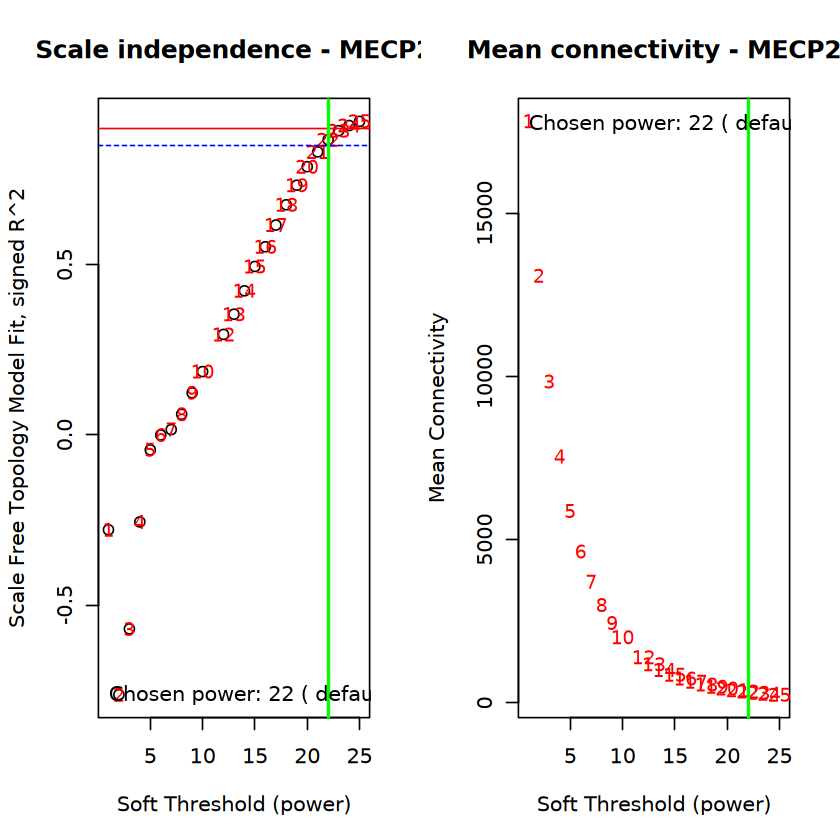

In [12]:
# Plot soft power thresholds for each cell line
for (cell_line in names(sft_results)) {
  if (!is.null(sft_results[[cell_line]])) {
    sft <- sft_results[[cell_line]]
    
    # Determine which power to use: default first, then secondary if no default
    default_power <- sft$powerEstimate
    final_power <- NA
    
    if (!is.na(default_power)) {
      final_power <- default_power
      power_source <- "default"
    } else {
      # Calculate secondary recommendation (min power with R² > 0.8)
      fit_indices <- sft$fitIndices
      R2_values <- fit_indices[, 2]
      powers <- fit_indices[, 1]
      valid_powers <- powers[R2_values > 0.8]
      
      if (length(valid_powers) > 0) {
        final_power <- min(valid_powers)
        power_source <- "secondary"
      }
    }
    
    par(mfrow = c(1, 2))
    cex1 = 0.9
    
    # Plot 1: Scale independence
    plot(sft$fitIndices[, 1],
         -sign(sft$fitIndices[, 3]) * sft$fitIndices[, 2],
         xlab = "Soft Threshold (power)",
         ylab = "Scale Free Topology Model Fit, signed R^2",
         main = paste("Scale independence -", cell_line)
    )
    text(sft$fitIndices[, 1],
         -sign(sft$fitIndices[, 3]) * sft$fitIndices[, 2],
         labels = powers, cex = cex1, col = "red"
    )
    abline(h = 0.90, col = "red")
    abline(h = 0.85, col = "blue", lty = 2)  # Add 0.85 threshold for reference
    
    # Mark the chosen power if available
    if (!is.na(final_power)) {
      abline(v = final_power, col = "green", lwd = 2)
      # Add legend to show which power was chosen and why
      legend("bottomright", 
             legend = paste("Chosen power:", final_power, "(", power_source, ")"),
             col = "green", lwd = 2, bty = "n")
    }
    
    # Plot 2: Mean connectivity
    plot(sft$fitIndices[, 1],
         sft$fitIndices[, 5],
         xlab = "Soft Threshold (power)",
         ylab = "Mean Connectivity",
         type = "n",
         main = paste("Mean connectivity -", cell_line)
    )
    text(sft$fitIndices[, 1],
         sft$fitIndices[, 5],
         labels = powers,
         cex = cex1, col = "red")
    
    # Mark the chosen power if available
    if (!is.na(final_power)) {
      abline(v = final_power, col = "green", lwd = 2)
      # Add legend to show which power was chosen and why
      legend("topright", 
             legend = paste("Chosen power:", final_power, "(", power_source, ")"),
             col = "green", lwd = 2, bty = "n")
    }
  }
}

# Reset plotting parameters
par(mfrow = c(1, 1))

### Module Generation

In [13]:
# Build Modules for each cell line using their recommended powers
networks <- list()

# Store original cor function
temp_cor <- cor       
cor <- WGCNA::cor # Force it to use WGCNA cor function

for (cell_line in names(sft_results)) {
    picked_power <- 22
    
    # Only proceed if we have a valid power
    if (!is.na(picked_power)) {
      counts_data <- datasets[[cell_line]]$counts
      
      cat(paste0("\nBuilding modules for ", cell_line, " with power = ", picked_power, " (", power_source, " recommendation)\n"))
      cat(paste0("Dataset dimensions: ", nrow(counts_data), " samples x ", ncol(counts_data), " genes\n"))
      
      netwk <- blockwiseModules(counts_data,
                                
                                # Other options
                                maxPOutliers = 0.1,
                                TOMType = "signed",
                                networkCalibration = "full quantile",
                                saveConsensusTOMs = TRUE,
                                
                                # == Adjacency Function ==
                                power = picked_power,                
                                networkType = "signed",
                                
                                # == Tree and Block Options ==
                                deepSplit = 2,
                                pamRespectsDendro = F,
                                # detectCutHeight = 0.75,
                                minModuleSize = 50,
                                maxBlockSize = 4000,
                                
                                # == Module Adjustments ==
                                reassignThreshold = 0,
                                mergeCutHeight = 0.1,
                                
                                # == TOM == Archive the run results in TOM file
                                saveTOMs = T,
                                saveTOMFileBase = paste0("TOM_", cell_line),
                                
                                # == Output Options
                                numericLabels = T,
                                verbose = 3)
      
      networks[[cell_line]] <- netwk
      
      cat(paste0("Completed module building for ", cell_line, "\n"))
      cat(paste0("Number of modules: ", length(unique(netwk$colors)), "\n"))
    } else {
      cat(paste0("Skipping ", cell_line, " - no valid power estimate available\n"))
    }
}

# Return cor function to original namespace
cor <- temp_cor


Building modules for MECP2 with power = 22 (default recommendation)
Dataset dimensions: 21 samples x 25210 genes
 Calculating module eigengenes block-wise from all genes
   Flagging genes and samples with too many missing values...
    ..step 1
  ..Excluding 56 genes from the calculation due to too many missing samples or zero variance.
  ..Excluding 5 samples from the calculation due to too many missing genes.
    ..step 2
 ....pre-clustering genes to determine blocks..
   Projective K-means:
   ..k-means clustering..
   ..merging smaller clusters...
Block sizes:
gBlocks
   1    2    3    4    5    6    7 
3995 3856 3821 3811 3630 3318 2723 
 ..Working on block 1 .
    TOM calculation: adjacency..
    ..will use 20 parallel threads.
     Fraction of slow calculations: 0.000000
    ..connectivity..
    ..matrix multiplication (system BLAS)..
    ..normalization..
    ..done.
   ..saving TOM for block 1 into file TOM_MECP2-block.1.RData
 ....clustering..
 ....detecting modules..
 ....c

In [14]:
# Iterate through each cell line and save module distributions
module_summaries <- list()

for (cell_line in names(networks)) {
  if (!is.null(networks[[cell_line]])) {
    cat(paste0("\nProcessing module distribution for: ", cell_line, "\n"))
    
    # Convert numeric module labels to module colors
    mergedColors <- labels2colors(networks[[cell_line]]$colors)
    
    # View module distribution as a table (number of genes per module)
    module_dist <- as.data.frame(table(mergedColors))
    module_dist <- module_dist[order(module_dist$Freq, decreasing = TRUE), ]
    colnames(module_dist) <- c("Module", "Genes")
    
    # Number of modules
    n_modules <- nrow(module_dist)
    cat(paste0("Number of modules: ", n_modules, "\n"))
    print(head(module_dist))
    
    # Save output with cell line-specific filename
    output_file <- paste0("08_WGCNA/", cell_line, "_gene_module_distribution.csv")
    write.csv(module_dist, output_file, row.names = FALSE)
    cat(paste0("Saved: ", output_file, "\n"))
    
    # Store summary information
    module_summaries[[cell_line]] <- list(
      n_modules = n_modules,
      total_genes = sum(module_dist$Genes),
      module_sizes = module_dist$Genes,
      largest_module = max(module_dist$Genes),
      smallest_module = min(module_dist$Genes)
    )
  }
}


Processing module distribution for: MECP2
Number of modules: 86
      Module Genes
81 turquoise  5748
4       blue  1702
6      brown   963
84    yellow   609
26     green   583
64       red   509
Saved: 08_WGCNA/MECP2_gene_module_distribution.csv


In [15]:
# Save dendrograms
for (cell_line in names(networks)) {
  if (!is.null(networks[[cell_line]])) {
    pdf(paste0("08_WGCNA/", cell_line, "_dendrogram.pdf"), width = 12, height = 8)
    
    mergedColors <- labels2colors(networks[[cell_line]]$colors)
    
    plotDendroAndColors(
      networks[[cell_line]]$dendrograms[[1]],
      mergedColors[networks[[cell_line]]$blockGenes[[1]]],
      main = paste("Gene Clustering -", cell_line),
      dendroLabels = FALSE,
      hang = 0.03,
      addGuide = TRUE,
      guideHang = 0.05
    )
    
    dev.off()
    cat(paste0("Saved: 08_WGCNA/", cell_line, "_dendrogram.pdf\n"))
  }
}

Saved: 08_WGCNA/MECP2_dendrogram.pdf


In [16]:
# Create and save module assignments for all cell lines
module_assignments <- list()

for (cell_line in names(networks)) {
  if (!is.null(networks[[cell_line]])) {
    cat(paste0("Processing module assignments for: ", cell_line, "\n"))
    
    # Pull out list of modules
    module_df <- data.frame(
      gene_id = colnames(datasets[[cell_line]]$counts),
      module_number = networks[[cell_line]]$colors,
      module_color = labels2colors(networks[[cell_line]]$colors)
    )
    
    # Sort by module number
    module_df <- module_df[order(module_df$module_number), ]
    
    # Save module assignments
    output_file <- paste0("08_WGCNA/", cell_line, "_gene_modules.txt")
    write.table(module_df, file = output_file, sep = "\t", row.names = FALSE, quote = FALSE)
    cat(paste0("Saved: ", output_file, "\n"))
    
    # Store in list for potential later use
    module_assignments[[cell_line]] <- module_df
    
    # Show summary
    n_modules <- length(unique(module_df$module_color))
    cat(paste0("Number of modules: ", n_modules, "\n"))
    print(head(module_df))
  }
}

Processing module assignments for: MECP2
Saved: 08_WGCNA/MECP2_gene_modules.txt
Number of modules: 86
                gene_id module_number module_color
ADD3-AS1       ADD3-AS1             0         grey
AMZ1               AMZ1             0         grey
ARNT2-AS1     ARNT2-AS1             0         grey
B4GALT4-AS1 B4GALT4-AS1             0         grey
BTG3-AS1       BTG3-AS1             0         grey
C19orf44       C19orf44             0         grey


### Module Eigengenes

In [17]:
# Calculate Module Eigengenes for all cell lines
MEs_list <- list()

for (cell_line in names(networks)) {
  if (!is.null(networks[[cell_line]])) {
    cat(paste0("Calculating Module Eigengenes for: ", cell_line, "\n"))
    
    # Get counts data for this cell line
    counts_data <- datasets[[cell_line]]$counts
    
    # Convert module labels to colors
    mergedColors <- labels2colors(networks[[cell_line]]$colors)
    
    # Get Module Eigengenes
    MEs0 <- moduleEigengenes(counts_data, mergedColors)$eigengenes
    
    # Reorder modules so similar modules are next to each other
    MEs0 <- orderMEs(MEs0)
    module_order <- names(MEs0) %>% gsub("ME", "", .)
    
    # Add sample names as a column
    MEs0$sample_id <- rownames(MEs0)
    
    # Store in list
    MEs_list[[cell_line]] <- MEs0
    
    # Save Module Eigengenes
    me_file <- paste0("08_WGCNA/", cell_line, "_module_eigengenes.txt")
    write.table(MEs0, file = me_file, sep = "\t", row.names = FALSE, quote = FALSE)
    cat(paste0("Saved: ", me_file, "\n"))
    
    # Show summary
    cat(paste0("Number of Module Eigengenes: ", ncol(MEs0) - 1, "\n"))  # -1 for sample_id column
    print(head(MEs0[, 1:min(6, ncol(MEs0))]))  # Show first few columns
  }
}

Calculating Module Eigengenes for: MECP2


Warning message in knnimp(x, k, maxmiss = rowmax, maxp = maxp):
“56 rows with more than 50 % entries missing;
 mean imputation used for these rows”


Saved: 08_WGCNA/MECP2_module_eigengenes.txt
Number of Module Eigengenes: 86
                                  MEgreen      MEplum       MEblack
2043_A_MECP2_R270X_CtO_D18_1  0.006176373  0.08470355 -0.0002369981
2043_A_MECP2_R270X_CtO_D18_2  0.029019139  0.09200988 -0.0002406956
2043_A_MECP2_R270X_CtO_D46_1 -0.498621600  0.07182097  0.0065042079
2043_A_MECP2_R270X_CtO_D46_2 -0.444879900 -0.59763010 -0.0004475250
2043_A_MECP2_R270X_CtO_D46_3 -0.005730593  0.11440275 -0.0001885302
2043_D_MECP2_WT_CtO_D18_1     0.033158640  0.09711892 -0.0002071821
                             MEfirebrick4       MEbrown      MEgrey60
2043_A_MECP2_R270X_CtO_D18_1 -0.008118945 -0.0001600609  0.0009493269
2043_A_MECP2_R270X_CtO_D18_2 -0.007835946 -0.0001453762  0.0009300213
2043_A_MECP2_R270X_CtO_D46_1  0.013992717 -0.0002393904 -0.0048766833
2043_A_MECP2_R270X_CtO_D46_2 -0.012978582  0.0034187789  0.0045690672
2043_A_MECP2_R270X_CtO_D46_3  0.006184464 -0.0001452568  0.0007746693
2043_D_MECP2_WT_CtO_D18_1   

In [18]:
# Calculate Module Membership for all cell lines
MM_list <- list()

for (cell_line in names(networks)) {
  if (!is.null(networks[[cell_line]]) && !is.null(MEs_list[[cell_line]])) {
    cat(paste0("Calculating Module Membership for: ", cell_line, "\n"))
    
    # Get counts data and MEs for this cell line
    counts_data <- datasets[[cell_line]]$counts
    MEs <- MEs_list[[cell_line]]
    
    # Extract just the ME values (remove sample_id column)
    me_values <- MEs[, !colnames(MEs) %in% "sample_id"]
    rownames(me_values) <- MEs$sample_id
    
    # Calculate module membership (bicor correlation between genes and MEs)
    moduleMembership <- bicorAndPvalue(counts_data, me_values,
                                      alternative = "two.sided", 
                                      use = "pairwise.complete.obs",
                                      maxPOutliers = 0.1)
    
    # Extract correlation values
    MM_cor <- as.data.frame(moduleMembership$bicor)
    colnames(MM_cor) <- gsub(pattern = "ME", replacement = "", x = colnames(MM_cor), fixed = TRUE)
    MM_cor$gene_id <- rownames(MM_cor)
    
    # Extract p-values
    MM_pval <- as.data.frame(moduleMembership$p)
    colnames(MM_pval) <- paste0(gsub(pattern = "ME", replacement = "", x = colnames(MM_pval), fixed = TRUE), "_pvalue")
    MM_pval$gene_id <- rownames(MM_pval)
    
    # Merge correlation and p-values
    MM <- merge(MM_cor, MM_pval, by = "gene_id")
    
    # Add module assignment
    mergedColors <- labels2colors(networks[[cell_line]]$colors)
    module_assign <- data.frame(gene_id = colnames(counts_data), 
                               module_color = mergedColors)
    MM <- merge(MM, module_assign, by = "gene_id")
    
    # Reorder columns
    mm_cols <- c("gene_id", "module_color")
    other_cols <- setdiff(colnames(MM), mm_cols)
    MM <- MM[, c(mm_cols, other_cols)]
    
    # Store in list
    MM_list[[cell_line]] <- MM
    
    # Save Module Membership
    mm_file <- paste0("08_WGCNA/", cell_line, "_module_membership.txt")
    write.table(MM, file = mm_file, sep = "\t", row.names = FALSE, quote = FALSE)
    cat(paste0("Saved: ", mm_file, "\n"))
    
    # Show summary
    cat(paste0("Module Membership dimensions: ", nrow(MM), " genes x ", ncol(MM), " columns\n"))
    print(head(MM[, 1:min(6, ncol(MM))]))
  }
}

Calculating Module Membership for: MECP2


Warning message in bicor(x, y, use = use, ...):
“bicor: zero MAD in variable 'x'. Pearson correlation was used for individual columns with zero (or missing) MAD.”
Warning message in pt(T, np - 2, lower.tail = FALSE):
“NaNs produced”


Saved: 08_WGCNA/MECP2_module_membership.txt
Module Membership dimensions: 25210 genes x 174 columns
   gene_id module_color      green        plum       black  firebrick4
1     A1BG     skyblue1  0.3337856  0.42767770  0.74019686 -0.14497411
2 A1BG-AS1         blue -0.1232945  0.07397340  0.42764393 -0.05033788
3     A1CF  saddlebrown -0.1676841  0.10379338  0.03614698  0.24452831
4      A2M  lightyellow  0.4481687 -0.15064426  0.22317382 -0.41102810
5  A2M-AS1  lightyellow  0.1726254  0.07070474  0.49606502 -0.31867584
6    A2ML1        black -0.2896420 -0.29996487 -0.06390512  0.19177024


### Get Module Hub Genes

In [19]:
# Identify hub genes for all cell lines
hub_genes_all <- list()

for (cell_line in names(MM_list)) {
  if (!is.null(MM_list[[cell_line]])) {
    cat(paste0("Identifying hub genes for: ", cell_line, "\n"))
    
    MM <- MM_list[[cell_line]]
    
    # Get module colors (excluding grey and any non-module columns)
    module_cols <- colnames(MM)[!colnames(MM) %in% c("gene_id", "module_color") & 
                                 !grepl("_pvalue$|_FDR$", colnames(MM))]
    
    # Get hub genes for each module
    hubGenes <- sapply(module_cols, function(x) {
      # Check if this is actually a module (should match module_color values)
      if (x %in% MM$module_color) {
        temp <- MM[MM$module_color == x, ]
        # Get gene with maximum correlation to the module
        if (nrow(temp) > 0 && x %in% colnames(temp)) {
          max_cor <- max(temp[, x], na.rm = TRUE)
          hub_gene <- temp$gene_id[temp[, x] == max_cor] %>% as.character() %>% unique() %>% sort()
          return(hub_gene)
        }
      }
      return(NA)
    })
    
    # Remove NULL/NA entries and grey module
    hubGenes <- hubGenes[!is.na(hubGenes)]
    hubGenes$grey <- NULL
    
    # Convert to data frame
    hub_df <- data.frame(
      module = names(hubGenes),
      hub_gene = unlist(hubGenes),
      cell_line = cell_line
    )
    
    # Add correlation value
    for (i in 1:nrow(hub_df)) {
      module <- hub_df$module[i]
      gene <- hub_df$hub_gene[i]
      hub_df$correlation[i] <- MM[MM$gene_id == gene & MM$module_color == module, module]
    }
    
    # Store in list
    hub_genes_all[[cell_line]] <- hub_df
    
    # Save hub genes for this cell line
    hub_file <- paste0("08_WGCNA/", cell_line, "_hub_genes.csv")
    write.csv(hub_df, hub_file, row.names = FALSE)
    cat(paste0("Saved: ", hub_file, "\n"))
    
    # Show summary
    cat(paste0("Number of hub genes identified: ", nrow(hub_df), "\n"))
    print(head(hub_df))
  }
}

Identifying hub genes for: MECP2


ERROR: Error in data.frame(module = names(hubGenes), hub_gene = unlist(hubGenes), : arguments imply differing number of rows: 85, 87, 1


### Module Trait Correlation (Correlate Module Eigengene Values to Traits)

In [20]:
# First, run the module-trait correlation analysis
module_trait_results <- list()

for (cell_line in names(MEs_list)) {
  if (!is.null(MEs_list[[cell_line]]) && !is.null(datasets[[cell_line]]$metadata)) {
    cat(paste0("Performing module-trait correlation for: ", cell_line, "\n"))
    
    # Get MEs and metadata
    MEs <- MEs_list[[cell_line]]
    metadata <- datasets[[cell_line]]$metadata
    
    # Extract just the ME values (remove sample_id column)
    me_values <- MEs[, !colnames(MEs) %in% "sample_id"]
    rownames(me_values) <- MEs$sample_id
    
    # Confirm sample order matches
    sample_match <- all(rownames(me_values) == rownames(metadata))
    cat(paste0("Sample order matches: ", sample_match, "\n"))
    
    if (!sample_match) {
      metadata <- metadata[rownames(me_values), ]
      cat("Reordered metadata to match MEs\n")
    }
    
    # Remove any non-numeric columns from metadata
    numeric_metadata <- metadata[, sapply(metadata, is.numeric)]
    
    # Pearson correlation
    moduleTraitCorP <- WGCNA::cor(me_values, numeric_metadata, method = "pearson", use = "pairwise.complete.obs")
    moduleTraitPvalueP <- corPvalueFisher(moduleTraitCorP, nrow(metadata), twoSided = TRUE)
    
    # Remove unwanted columns if they exist
    cols_to_remove <- c("Treatment", "Sex", "sample_id")
    moduleTraitCorP <- moduleTraitCorP[, !colnames(moduleTraitCorP) %in% cols_to_remove, drop = FALSE]
    moduleTraitPvalueP <- moduleTraitPvalueP[, !colnames(moduleTraitPvalueP) %in% cols_to_remove, drop = FALSE]
    
    # Remove any rows that are all NA
    na_rows <- apply(moduleTraitCorP, 1, function(x) all(is.na(x)))
    moduleTraitCorP <- moduleTraitCorP[!na_rows, , drop = FALSE]
    moduleTraitPvalueP <- moduleTraitPvalueP[!na_rows, , drop = FALSE]
    
    # Store results
    module_trait_results[[cell_line]] <- list(
      correlation = moduleTraitCorP,
      pvalue = moduleTraitPvalueP
    )
  }
}

Performing module-trait correlation for: MECP2
Sample order matches: TRUE


Warning message in WGCNA::cor(me_values, numeric_metadata, method = "pearson", use = "pairwise.complete.obs"):
“Missing values generated in calculation of cor. Likely cause: too many missing entries or zero variance.”


In [21]:
# Identify significant module-trait associations
significant_associations <- list()

for (cell_line in names(module_trait_results)) {
  result <- module_trait_results[[cell_line]]
  cor_matrix <- result$correlation
  pval_matrix <- result$pvalue
  
  # Find significant correlations (p < 0.05)
  sig_indices <- which(pval_matrix < 0.05, arr.ind = TRUE)
  
  if (length(sig_indices) > 0) {
    sig_associations <- data.frame(
      cell_line = cell_line,
      module = rownames(cor_matrix)[sig_indices[, 1]],
      trait = colnames(cor_matrix)[sig_indices[, 2]],
      correlation = cor_matrix[sig_indices],
      pvalue = pval_matrix[sig_indices]
    )
    
    # Sort by absolute correlation
    sig_associations <- sig_associations[order(-abs(sig_associations$correlation)), ]
    
    significant_associations[[cell_line]] <- sig_associations
    
    # Save significant associations
    sig_file <- paste0("08_WGCNA/", cell_line, "_significant_associations.txt")
    write.table(sig_associations, sig_file, sep = "\t", row.names = FALSE, quote = FALSE)
    cat(paste0("Saved significant associations: ", sig_file, "\n"))
    
    cat(paste0("Significant associations for ", cell_line, ": ", nrow(sig_associations), "\n"))
    print(head(sig_associations))
  } else {
    cat(paste0("No significant associations found for ", cell_line, "\n"))
  }
}

Saved significant associations: 08_WGCNA/MECP2_significant_associations.txt
Significant associations for MECP2: 1655
    cell_line         module                  trait correlation pvalue
320     MECP2  MEfloralwhite WT_D18_vs_R270X_pA_D90          -1      0
327     MECP2     MEmagenta4 WT_D18_vs_R270X_pD_D90          -1      0
328     MECP2       MEorange WT_D18_vs_R270X_pD_D90          -1      0
330     MECP2     MEdarkgrey WT_D18_vs_R270X_pD_D90          -1      0
331     MECP2     MEskyblue3 WT_D18_vs_R270X_pD_D90          -1      0
332     MECP2 MEmediumorchid WT_D18_vs_R270X_pD_D90          -1      0


In [22]:
# Function to create heatmap
create_module_trait_heatmap <- function(cor_matrix, pval_matrix, cell_line) {
  # Calculate dynamic dimensions based on data size
  n_modules <- nrow(cor_matrix)
  n_traits <- ncol(cor_matrix)
  
  # Adjust plot dimensions based on data size
  plot_width <- max(10, min(18, n_traits * 0.8 + 7))
  plot_height <- max(10, min(22, n_modules * 0.5 + 9))
    
  # Create significance asterisks
  star <- apply(pval_matrix, 2, function(x) {
    sapply(x, function(y) {
      ifelse(y < 0.001, "***", 
             ifelse(y < 0.01, "**", 
                    ifelse(y < 0.05, "*", "")))
    })
  })
  
  # Set up PDF
  pdf_file <- paste0("08_WGCNA/", cell_line, "_module_trait_heatmap.pdf")
  pdf(pdf_file, width = plot_width, height = plot_height)
  
  # Use a 2x2 grid layout for control adding legends
  layout(matrix(c(1, 1, 2, 3), 2, 2, byrow = TRUE), 
         widths = c(0.85, 0.15),  # 85% heatmap, 15% legends
         heights = c(0.9, 0.1))  # 90% heatmap, 10% bottom space
  
  # Main heatmap plot
  par(mar = c(
    max(12, n_traits * 1.1), 
    max(6, n_modules * 0.15), 
    6,                      
    2                        
  ))
  
  # Adjust text size
  cex_text <- ifelse(n_modules > 50, 0.8, 
                    ifelse(n_modules > 30, 0.9, 1.0))
  
  cex_labels <- ifelse(n_traits > 15, 0.7, 
                      ifelse(n_traits > 10, 0.8, 0.9))
  
  # Plot the heatmap
  labeledHeatmap(
    Matrix = cor_matrix,
    xLabels = colnames(cor_matrix),
    xLabelsAngle = 90, 
    xLabelsAdj = c(1, 0.5),
    yLabels = rownames(cor_matrix),
    ySymbols = gsub("ME", "", rownames(cor_matrix)),
    colorLabels = FALSE,
    colors = blueWhiteRed(50),
    textMatrix = star,
    setStdMargins = FALSE,
    cex.text = cex_text, 
    textAdj = c(0.5, 0.8),
    zlim = c(-1, 1),
    main = paste("Module-Trait Correlation -", cell_line),
    cex.lab.x = cex_labels, 
    cex.lab.y = cex_labels,
    plotLegend = FALSE, 
    xLabelsPosition = "bottom"
  )
  
  # Color legend
  par(mar = c(3, 2, 3, 4))
  plot.new()
  # Create custom color legend
  plot.window(xlim = c(0, 1), ylim = c(0, 1))
  gradient <- blueWhiteRed(50)
  x_pos <- seq(0.1, 0.9, length.out = 50)
  
  # Draw color gradient
  for (i in 1:50) {
    rect(x_pos[i], 0.3, x_pos[i] + 0.016, 0.7, col = gradient[i], border = NA)
  }
  
  # Add labels 
  text(x = c(0.1, 0.5, 0.9), y = 0.2, 
       labels = c("-1", "0", "1"), cex = 0.9)
  text(x = 0.5, y = 0.9, "Pearson Correlation", cex = 1.0, font = 2)
  
  # Significance legend
  par(mar = c(3, 2, 3, 4))
  plot.new()
  legend("center", 
         legend = c("*** p < 0.001", "** p < 0.01", "* p < 0.05"),
         pch = "*", 
         pt.cex = c(1.5, 1.5, 1.5),  
         cex = 0.9,              
         bty = "n",
         title = "Significance",
         title.adj = 0.5,
         ncol = 1)
  
  # Close the PDF device
  dev.off()
  
  cat(paste0("Saved heatmap: ", pdf_file, 
             " (", round(plot_width, 1), "\" x ", round(plot_height, 1), "\")\n"))
  
  return(pdf_file)
}

In [23]:
# Create heatmaps 
heatmap_files <- list()

for (cell_line in names(module_trait_results)) {
  if (!is.null(module_trait_results[[cell_line]])) {
    result <- module_trait_results[[cell_line]]
    cor_matrix <- result$correlation
    pval_matrix <- result$pvalue
    
    # Only create heatmap if there are modules and traits
    if (nrow(cor_matrix) > 0 && ncol(cor_matrix) > 0) {
      cat(paste0("Creating heatmap for: ", cell_line, "\n"))
      cat(paste0("Dimensions: ", nrow(cor_matrix), " modules x ", ncol(cor_matrix), " traits\n"))
      
      heatmap_file <- create_module_trait_heatmap(cor_matrix, pval_matrix, cell_line)
      heatmap_files[[cell_line]] <- heatmap_file
    } else {
      cat(paste0("Skipping ", cell_line, " - no modules or traits to plot\n"))
    }
  }
}

Creating heatmap for: MECP2
Dimensions: 86 modules x 37 traits
Saved heatmap: 08_WGCNA/MECP2_module_trait_heatmap.pdf (18" x 22")


In the above figure generate, blue is correlated with whatever we coded as 0 and red is correlated with whatever we coded as 1. Anything with a star means it's a significant correlation